# 05 · Placar das três configurações e erros reais

Configurações: `sem_contexto` (linha de base), `rag` (top-3 + limiar) e `rag_lora` (mesmo prompt +
adaptador). As linhas `*_sem_limiar` mostram o efeito isolado do portão por similaridade.

Métricas: acerto nas `responde` (todos os fatos-chave e sem recusa), recusa correta nas `nao_consta`,
alucinação (respondeu uma `nao_consta`), erro factual (respondeu uma `responde` faltando fatos), recusa
indevida, JSON válido estrito, citação correta, acurácia global, latência média e p95.

> Pré-requisitos: ambiente instalado (`pip install -e .` na raiz) e dados em `base/`, `avaliacao/` e `treino/`. Rode as células em ordem. `REEXECUTAR = False` reaproveita os resultados já gravados para a reexecução ser rápida.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from alerta_ia import config, dados

pd.set_option("display.max_colwidth", 160)
REEXECUTAR = False  # True = refaz as etapas pesadas (GPU) em vez de ler os resultados gravados


def rodar(*args):
    """Executa um módulo do projeto (python -m ...) na raiz do repositório e mostra a saída."""
    r = subprocess.run([sys.executable, "-m", *args], cwd=config.RAIZ, capture_output=True, text=True,
                       encoding="utf-8", errors="replace")
    print(r.stdout[-4000:])
    if r.returncode != 0:
        print(r.stderr[-4000:])
        raise RuntimeError(f"falha ao executar {args}")


def ler_json(caminho):
    return json.loads(Path(caminho).read_text(encoding="utf-8"))

In [2]:
from alerta_ia import avaliacao

if REEXECUTAR:
    rodar("alerta_ia.avaliacao", "--config", "todas")
    rodar("alerta_ia.avaliacao", "--config", "todas", "--sem-limiar")
placar = avaliacao.consolidar_placar()
display(Markdown(config.PLACAR_MD.read_text(encoding="utf-8")))

# Placar

| Configuração        | Acurácia global   | Acerto (responde)   | Fatos cobertos   | Precisão quando responde   | Recusa correta (não consta)   | Alucinação   | Erro factual   | Recusa indevida   | JSON válido (estrito)   | Citação correta   |   Latência média (ms) |   Latência p95 (ms) |
|---------------------|-------------------|---------------------|------------------|----------------------------|-------------------------------|--------------|----------------|-------------------|-------------------------|-------------------|-----------------------|---------------------|
| sem_contexto        | 30.0%             | 0.0%                | 4.4%             | 0.0%                       | 100.0%                        | 0.0%         | 19.1%          | 81.0%             | 100.0%                  | 0.0%              |                  3580 |                5558 |
| rag                 | 66.7%             | 52.4%               | 57.1%            | 73.3%                      | 100.0%                        | 0.0%         | 19.1%          | 28.6%             | 100.0%                  | 71.4%             |                  5170 |               10844 |
| rag_lora            | 66.7%             | 52.4%               | 67.5%            | 56.4%                      | 100.0%                        | 0.0%         | 40.5%          | 7.1%              | 100.0%                  | 85.7%             |                  7488 |               12703 |
| rag_sem_limiar      | 66.7%             | 52.4%               | 57.1%            | 73.3%                      | 100.0%                        | 0.0%         | 19.1%          | 28.6%             | 100.0%                  | 71.4%             |                  5030 |                8586 |
| rag_lora_sem_limiar | 66.7%             | 52.4%               | 67.5%            | 56.4%                      | 100.0%                        | 0.0%         | 40.5%          | 7.1%              | 100.0%                  | 85.7%             |                  8797 |               11395 |

Gerado em 2026-11-15T20:58:10. Conjunto: teste.jsonl.

- Acerto (responde): todos os fatos-chave presentes e sem recusa.
- Fatos cobertos: média da fração de fatos-chave presentes (crédito parcial; recusa = 0).
- Precisão quando responde: das perguntas `responde` que o modelo não recusou, quantas acertou.
- Recusa correta / Alucinação: sobre as perguntas `nao_consta` (somam 100%).
- Erro factual e recusa indevida: sobre as perguntas `responde`.
- JSON válido (estrito): `json.loads` do texto bruto + exatamente os 3 campos, sobre as chamadas à LLM (recusas pelo limiar não chamam a LLM).
- Citação correta: `responde` em que `fontes` contém um trecho relevante e nenhum id fora do contexto.
- Linhas `*_sem_limiar`: mesmas configurações com o portão por similaridade desligado.


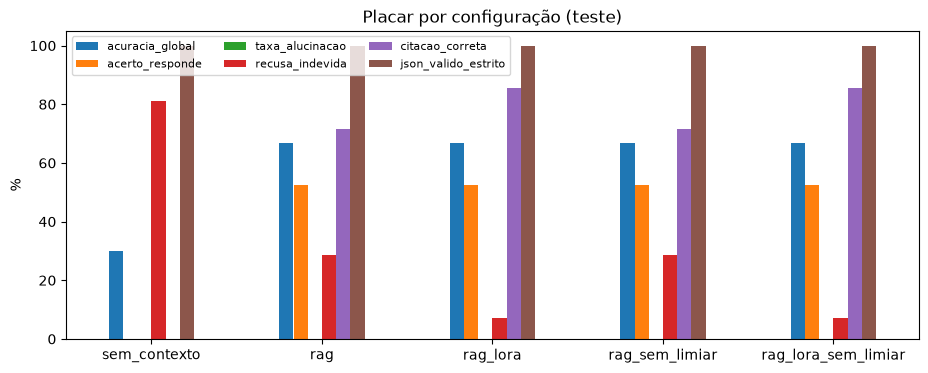

In [3]:
m = pd.DataFrame({n: p["metricas"] for n, p in placar["configuracoes"].items()}).T
ordem = [n for n in avaliacao.ORDEM if n in m.index] + [n for n in m.index if n not in avaliacao.ORDEM]
m = m.loc[ordem]
principais = ["acuracia_global", "acerto_responde", "taxa_alucinacao", "recusa_indevida", "citacao_correta",
              "json_valido_estrito"]
ax = (m[principais].astype(float) * 100).plot.bar(figsize=(11, 4), rot=0)
ax.set_ylabel("%"); ax.set_title("Placar por configuração (teste)"); ax.legend(fontsize=8, ncol=3);

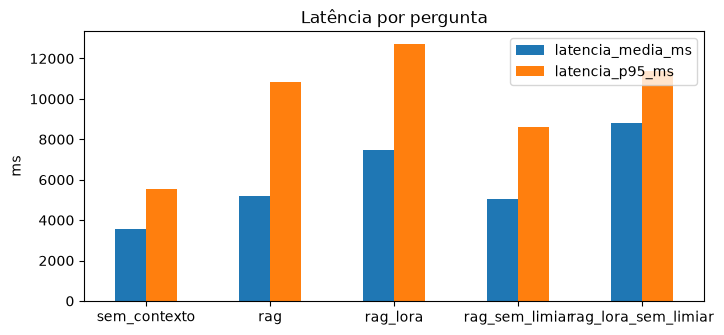

In [4]:
ax = m[["latencia_media_ms", "latencia_p95_ms"]].astype(float).plot.bar(figsize=(8, 3.5), rot=0)
ax.set_ylabel("ms"); ax.set_title("Latência por pergunta");

## Efeito isolado do limiar

In [5]:
pares = [(c, f"{c}_sem_limiar") for c in ["rag", "rag_lora"] if c in m.index and f"{c}_sem_limiar" in m.index]
if not pares:
    print("Rode `python -m alerta_ia.avaliacao --config todas --sem-limiar` para ver o efeito do limiar.")
for com, sem in pares:
    t = m.loc[[sem, com], ["acerto_responde", "taxa_alucinacao", "recusa_indevida", "recusas_por_limiar",
                           "chamadas_llm", "latencia_media_ms"]]
    display(t)

,acerto_responde,taxa_alucinacao,recusa_indevida,recusas_por_limiar,chamadas_llm,latencia_media_ms
rag_sem_limiar,0.5238,0.0,0.2857,0.0,60.0,5030.5
rag,0.5238,0.0,0.2857,10.0,50.0,5170.3


,acerto_responde,taxa_alucinacao,recusa_indevida,recusas_por_limiar,chamadas_llm,latencia_media_ms
rag_lora_sem_limiar,0.5238,0.0,0.0714,0.0,60.0,8797.1
rag_lora,0.5238,0.0,0.0714,10.0,50.0,7487.5


## Leitura do placar

Compare `rag` e `rag_lora` com `sem_contexto`: a hipótese do projeto é **mais acerto** e **menos
alucinação** com contexto, mantendo JSON válido e citação verificável. A interpretação final, com os números
reais, está no relatório.

In [6]:
base = m.loc["sem_contexto"] if "sem_contexto" in m.index else None
if base is not None:
    for cfg in [c for c in ["rag", "rag_lora"] if c in m.index]:
        print(f"{cfg} vs sem_contexto: acurácia {100 * (m.loc[cfg, 'acuracia_global'] - base['acuracia_global']):+.1f} p.p.,"
              f" alucinação {100 * (m.loc[cfg, 'taxa_alucinacao'] - base['taxa_alucinacao']):+.1f} p.p.")

rag vs sem_contexto: acurácia +36.7 p.p., alucinação +0.0 p.p.
rag_lora vs sem_contexto: acurácia +36.7 p.p., alucinação +0.0 p.p.


## Candidatos a erros reais

Todos os casos com falha, por tipo: busca não trouxe o trecho, recusa indevida, alucinação, JSON inválido,
citação errada, fato faltando. A lista completa está em `avaliacao/erros_candidatos.md`; os 5 erros
analisados no relatório saem daqui.

In [7]:
resultados = avaliacao.carregar_resultados()
linhas = []
for nome, regs in resultados.items():
    for r in regs:
        for f in r["metricas"]["falhas"][:1]:
            linhas.append({"configuracao": nome, "falha_principal": avaliacao.FALHAS[f], "id": r["id"]})
falhas = pd.DataFrame(linhas)
if falhas.empty:
    print("nenhuma falha registrada")
else:
    display(pd.crosstab(falhas["falha_principal"], falhas["configuracao"], margins=True, margins_name="total"))

configuracao,rag,rag_lora,rag_lora_sem_limiar,rag_sem_limiar,sem_contexto,total
falha_principal,,,,,,
busca não trouxe o trecho relevante,3,3,3,3,0,12
fato-chave faltando na resposta,7,14,14,7,8,50
recusa indevida,10,3,3,10,34,60
total,20,20,20,20,42,122


In [8]:
alvo = "rag_lora" if "rag_lora" in resultados else next(iter(resultados), None)
if alvo:
    df = pd.DataFrame(resultados[alvo])
    df["falha"] = df["metricas"].apply(lambda x: ", ".join(avaliacao.FALHAS[f] for f in x["falhas"]))
    display(df[df["falha"] != ""][["id", "tipo", "pergunta", "resposta", "fontes", "trechos_relevantes", "falha"]]
            .head(15))

,id,tipo,pergunta,resposta,fontes,trechos_relevantes,falha
5,T006,responde,dá pra cadastrar mais de um cep no 40199?,Pode. Envie uma mensagem por vez para cada CEP que deseja cadastrar.,[SEMIL-01-010],[SEMIL-01-010],fato-chave faltando na resposta
6,T007,responde,precisa ter internet pro alerta da defesa civil aparecer na tela do celular?,"Não. Os alertas aparecem diretamente na tela dos celulares compatíveis localizados em áreas de risco, sem precisar de conexão com a internet.","[MIDR-02-004, MIDR-01-001]",[MIDR-02-004],fato-chave faltando na resposta
10,T011,responde,"Meu filho quer brincar na enxurrada, tem problema?",Não. Não deixe as crianças brincarem nas águas da inundação.,[MS-03-019],[COMDEC-01-005],"busca não trouxe o trecho relevante, fato-chave faltando na resposta, citação errada ou ausente"
11,T012,responde,como sei se vai ter deslizamento no morro? quais sinais?,"Observar rachaduras, trincas ou saliências no chão ou nas paredes, e água mais barrenta que o normal, pode indicar um deslizamento.",[DCSP-01-003],"[DCSP-01-003, MCID-01-004]",fato-chave faltando na resposta
13,T014,responde,Quais os sintomas da leptospirose?,"Fevere, falta de apetite, dor muscular (principalmente na panturrilha), dor de cabeça e náuseas ou vômitos. Também podem ocorrer diarreia, dor nas articulaç...",[MS-02-003],"[MS-02-003, COMDEC-01-007]",fato-chave faltando na resposta
17,T018,responde,"Se eu for pra um abrigo, posso deixar meu cachorro em casa?",Não. Os animais domésticos podem não sobreviver ou se perder antes que vocês voltem.,[MS-03-016],[MS-03-016],fato-chave faltando na resposta
18,T019,responde,"tô de carro e a rua encheu dagua, passo ou não?","Não. Se precisar atravessar ruas alagadas, use muros e paredes como apoio ou cordas, com ajuda de pelo menos três pessoas.",[MCID-01-007],"[MCID-01-007, MIDR-03-004]",fato-chave faltando na resposta
19,T020,responde,"a casa alagou e depois secou, posso ligar a geladeira que molhou?",Não. Mantenha objetos de valor em locais altos e esvazie a geladeira.,[MCID-01-005],"[COMDEC-01-008, MS-03-019]","fato-chave faltando na resposta, citação errada ou ausente"
20,T021,responde,"a parede ficou com mofo preto depois da enchente, como limpo?","Lave, desinfete e deixe o local bem ventilado.",[SMSSP-01-007],[SMSSP-01-007],fato-chave faltando na resposta
24,T025,responde,quantos litros de agua por pessoa no kit?,"Não consta na base. Os documentos oficiais que eu uso não trazem essa informação; para isso, procure a prefeitura ou o órgão responsável.",[],[ABR-01-001],"recusa indevida, citação errada ou ausente"
